# Speech command classification

This experiment uses local Speech Commands WAV files in `speech_commands/<class>/`. The dataset and pretrained model weights are not included. Training, validation and test partitions are disjoint at the file level. The local filenames do not preserve speaker identifiers, so the split cannot guarantee separation by speaker; scores can overestimate performance on new speakers. The saved results were generated on Kaggle with the corrected split and evaluated on the held-out test files.

**Data:** A local seven-class speech-command WAV collection under `speech_commands/<class>/`. The exact original public source is not confirmed. The exact files used in the saved experiments are not included; provide a compatible seven-class collection to run the notebook.

## Raw audio → causal dilated 1D convolutions (WaveNet / TCN) → residual + skip connections → global pooling → classifier

In [1]:
import os
import torch
import torchaudio
import soundfile as sf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

SAMPLE_RATE = 16000
BATCH_SIZE = 16
EPOCHS = 40

CLASSES = ['down', 'left', 'off', 'on', 'right', 'stop', 'up']
NUM_CLASSES = len(CLASSES)

MAX_LEN = SAMPLE_RATE

In [2]:
class SpeechCommandsDataset(Dataset):
    def __init__(self, root_dir, classes):
        self.files = []
        self.labels = []

        for label, cls in enumerate(classes):
            cls_dir = os.path.join(root_dir, cls)
            for fname in sorted(os.listdir(cls_dir)):
                if fname.endswith(".wav"):
                    self.files.append(os.path.join(cls_dir, fname))
                    self.labels.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        wav_np, sr = sf.read(self.files[idx], dtype="float32")
        waveform = torch.from_numpy(wav_np)

        if waveform.ndim == 1:
            pass
        else:
            waveform = waveform.mean(dim=1)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE)

        # Pad / truncate
        if waveform.shape[0] < MAX_LEN:
            pad = MAX_LEN - waveform.shape[0]
            waveform = F.pad(waveform, (0, pad))
        else:
            waveform = waveform[:MAX_LEN]

        return waveform.unsqueeze(0), self.labels[idx]

In [3]:
class CausalConv1d(nn.Conv1d):
    def __init__(self, *args, **kwargs):
        kwargs.setdefault("padding", 0)
        super().__init__(*args, **kwargs)
        self.left_padding = (self.kernel_size[0] - 1) * self.dilation[0]

    def forward(self, x):
        x = F.pad(x, (self.left_padding, 0))
        return super().forward(x)


In [4]:
class WaveNetBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()

        self.filter_conv = CausalConv1d(
            channels, channels, kernel_size=2, dilation=dilation
        )
        self.gate_conv = CausalConv1d(
            channels, channels, kernel_size=2, dilation=dilation
        )

        self.residual = nn.Conv1d(channels, channels, kernel_size=1)
        self.skip = nn.Conv1d(channels, channels, kernel_size=1)

    def forward(self, x):
        f = torch.tanh(self.filter_conv(x))
        g = torch.sigmoid(self.gate_conv(x))
        z = f * g

        return self.residual(z) + x, self.skip(z)

In [5]:
class WaveNetClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.input_conv = nn.Conv1d(1, 64, kernel_size=1)

        self.blocks = nn.ModuleList()
        dilations = [1, 2, 4, 8, 16, 32]

        for d in dilations:
            self.blocks.append(WaveNetBlock(64, d))

        self.output = nn.Sequential(
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.input_conv(x)

        skip_connections = []

        for block in self.blocks:
            x, skip = block(x)
            skip_connections.append(skip)

        x = sum(skip_connections)
        return self.output(x)

In [6]:
DATA_ROOT = os.environ.get("SPEECH_COMMANDS_ROOT", "speech_commands")
dataset = SpeechCommandsDataset(DATA_ROOT, CLASSES)
indices = np.arange(len(dataset))
labels = np.asarray(dataset.labels)
train_val_idx, test_idx = train_test_split(indices, test_size=0.15, random_state=42, stratify=labels)
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.1765, random_state=42, stratify=labels[train_val_idx])
train_ds = torch.utils.data.Subset(dataset, train_idx)
val_ds = torch.utils.data.Subset(dataset, val_idx)
test_ds = torch.utils.data.Subset(dataset, test_idx)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_ds)}, validation: {len(val_ds)}, test: {len(test_ds)}")

Train: 11529, validation: 2471, test: 2471


In [7]:
model = WaveNetClassifier(NUM_CLASSES).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

BEST_MODEL_PATH = "best_wavenet_speech.pt"
CHECKPOINT_PATH = "wavenet_checkpoint.pt"

RESUME_TRAINING = False  # Old checkpoints used a different split; train afresh.
MANUAL_START_EPOCH = 7

In [8]:
start_epoch = 0
best_acc = -float("inf")
best_epoch = 0

if RESUME_TRAINING and os.path.exists(CHECKPOINT_PATH):
    ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt.get("best_acc", 0.0)
    best_epoch = ckpt.get("best_epoch", 0)
    print(f"Resume from checkpoint: epoch {start_epoch}/{EPOCHS}, best_acc={best_acc:.4f}")
elif RESUME_TRAINING and os.path.exists(BEST_MODEL_PATH):
    model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
    start_epoch = MANUAL_START_EPOCH
    print(f"Checkpoint not found. Loaded best weights, continue from epoch {start_epoch}/{EPOCHS}")

for epoch in range(start_epoch, EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for x, y in tqdm(train_loader, desc=f"Train {epoch+1}/{EPOCHS}"):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(logits, dim=1)
        train_correct += (preds == y).sum().item()
        train_total += y.size(0)

    train_loss /= len(train_loader)
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in tqdm(val_loader, desc=f"Val   {epoch+1}/{EPOCHS}"):
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(x)
            loss = criterion(logits, y)

            val_loss += loss.item()
            preds = torch.argmax(logits, dim=1)
            val_correct += (preds == y).sum().item()
            val_total += y.size(0)

    val_loss /= len(val_loader)
    val_acc = val_correct / val_total

    print(
        f"[{epoch+1:2d}/{EPOCHS}] "
        f"train loss: {train_loss:.4f}  acc: {train_acc:.4f} | "
        f"val loss: {val_loss:.4f}  acc: {val_acc:.4f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"-> new best model saved (acc = {val_acc:.4f})")

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_acc": best_acc,
            "best_epoch": best_epoch,
        },
        CHECKPOINT_PATH,
    )

print(f"\nBest val accuracy: {best_acc:.4f} at epoch {best_epoch}")

Train 1/40:   0%|          | 0/721 [00:00<?, ?it/s]

Val   1/40:   0%|          | 0/155 [00:00<?, ?it/s]

[ 1/40] train loss: 1.9488  acc: 0.1406 | val loss: 1.9465  acc: 0.1457
-> new best model saved (acc = 0.1457)


Train 2/40:   0%|          | 0/721 [00:00<?, ?it/s]

Val   2/40:   0%|          | 0/155 [00:00<?, ?it/s]

[ 2/40] train loss: 1.8504  acc: 0.2284 | val loss: 1.7064  acc: 0.3161
-> new best model saved (acc = 0.3161)


... (110 outputs left out)

[39/40] train loss: 0.6386  acc: 0.7965 | val loss: 0.8057  acc: 0.7503


Train 40/40:   0%|          | 0/721 [00:00<?, ?it/s]

Val   40/40:   0%|          | 0/155 [00:00<?, ?it/s]

[40/40] train loss: 0.6355  acc: 0.7943 | val loss: 0.8426  acc: 0.7442

Best val accuracy: 0.7580 at epoch 31


In [9]:
model.load_state_dict(torch.load("best_wavenet_speech.pt", map_location=DEVICE, weights_only=True))
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(DEVICE))
        preds = torch.argmax(logits, dim=1)

        y_true.extend(y.numpy())
        y_pred.extend(preds.cpu().numpy())

Accuracy: 0.764063132335087
              precision    recall  f1-score   support

        down     0.7031    0.7649    0.7327       353
        left     0.7486    0.7677    0.7580       353
         off     0.8552    0.7025    0.7714       353
          on     0.7833    0.7167    0.7485       353
       right     0.8243    0.7309    0.7748       353
        stop     0.8780    0.8357    0.8563       353
          up     0.6328    0.8300    0.7181       353

    accuracy                         0.7641      2471
   macro avg     0.7750    0.7641    0.7657      2471
weighted avg     0.7750    0.7641    0.7657      2471



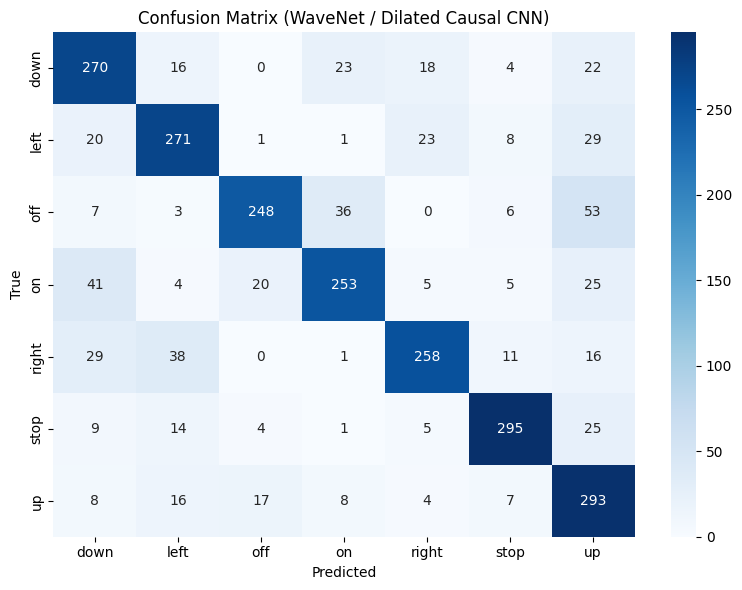

In [10]:
print("Accuracy:", accuracy_score(y_true, y_pred))

print(
    classification_report(
        y_true, y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASSES,
        zero_division=0,
        digits=4
    )
)

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (WaveNet / Dilated Causal CNN)")
plt.tight_layout()
plt.show()
